# Análisis de ventas de videojuegos

## Objetivo
Analizar datos históricos de videojuegos para identificar patrones de ventas por plataforma, género y región, y evaluar qué factores pueden ayudar a detectar títulos con potencial comercial.

**Contexto:** el análisis simula una decisión tomada a finales de 2016 para orientar una campaña de 2017. Por ello, las conclusiones se interpretan desde esa perspectiva temporal.

**Herramientas:** Python, pandas, NumPy, Matplotlib, Seaborn y SciPy.

> Antes de ejecutar el notebook, coloca el archivo `games.csv` en la misma carpeta que este notebook.


----

# Paso 1. Abre el archivo de datos y estudia la información general

In [1]:
import pandas as pd
import numpy as np

games = pd.read_csv('../datos/games.csv')
games.columns = games.columns.str.lower()

print(games.info())
print(games.head())

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  str    
 1   platform         16715 non-null  str    
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  str    
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  str    
 10  rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 2.0 MB
None
                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super Mario Bros.      NES           1985.0      Platform     29.08   
2       

# Paso 2. Prepara los datos

En esta etapa se normalizan los nombres de las columnas, se revisan los tipos de datos y se documenta el tratamiento de valores ausentes. Las decisiones de limpieza se toman antes de interpretar los resultados para reducir el riesgo de sesgo.\n

In [2]:
# Eliminar registros sin nombre o género, necesarios para identificar y analizar cada juego.
games = games.dropna(subset=['name', 'genre']).copy()

# Convertir el año a un tipo entero que admite valores ausentes.
# No imputamos años: una mediana global podría asignar un año imposible para ciertas plataformas.
games['year_of_release'] = pd.to_numeric(
    games['year_of_release'], errors='coerce'
).astype('Int64')

# "TBD" significa que la calificación de usuarios todavía no estaba determinada.
# Se convierte en NaN y se conserva como dato ausente; no se imputan calificaciones.
games['user_score'] = games['user_score'].replace('tbd', np.nan)
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')
games['critic_score'] = pd.to_numeric(games['critic_score'], errors='coerce')

# Mantener los registros sin clasificación ESRB y etiquetarlos explícitamente.
games['rating'] = games['rating'].fillna('Unknown')

# Calcular las ventas globales sumando las cuatro regiones.
sales_columns = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
games['total_sales'] = games[sales_columns].sum(axis=1)

# Resumen para validar los tipos y los valores ausentes después de la preparación.
display(games.info())
print('Valores ausentes por columna:')
display(games.isna().sum().sort_values(ascending=False))
display(games.head())


<class 'pandas.DataFrame'>
Index: 16713 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  str    
 1   platform         16713 non-null  str    
 2   year_of_release  16444 non-null  Int64  
 3   genre            16713 non-null  str    
 4   na_sales         16713 non-null  float64
 5   eu_sales         16713 non-null  float64
 6   jp_sales         16713 non-null  float64
 7   other_sales      16713 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           16713 non-null  str    
 11  total_sales      16713 non-null  float64
dtypes: Int64(1), float64(7), str(4)
memory usage: 2.3 MB


None

Valores ausentes por columna:


user_score         9123
critic_score       8576
year_of_release     269
name                  0
genre                 0
platform              0
na_sales              0
eu_sales              0
other_sales           0
jp_sales              0
rating                0
total_sales           0
dtype: int64

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,Unknown,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,Unknown,31.38


### Tratamiento de los valores ausentes

- **`name` y `genre`:** se eliminaron las filas sin estos campos porque son necesarios para identificar y analizar cada videojuego.
- **`year_of_release`:** se conservaron los valores ausentes. Imputar con la mediana global podría asignar años poco plausibles, especialmente si la plataforma apareció mucho después.
- **`user_score`:** los valores `TBD` se convirtieron en ausentes porque la calificación aún no estaba determinada. No se imputaron puntuaciones para evitar alterar su distribución.
- **`critic_score`:** se conservaron los valores ausentes porque no hay evidencia suficiente para estimar una calificación fiable.
- **`rating`:** los valores ausentes se etiquetaron como `Unknown`, para distinguirlos de las clasificaciones conocidas sin eliminar esos juegos.

No se eliminaron filas por tener calificaciones o años ausentes, ya que eso reduciría la información disponible para otros análisis.


### Posibles causas de los valores ausentes

Los valores ausentes pueden deberse a registros históricos incompletos, información que no se recopiló o calificaciones que todavía no estaban disponibles. En particular, `TBD` indica que la calificación de usuarios estaba pendiente.

Estas son explicaciones posibles; el conjunto de datos no permite confirmar la causa de cada valor ausente.


### Tratamiento de `TBD`

`TBD` significa *to be determined* (por determinar). En `user_score`, se reemplazó por un valor ausente (`NaN`) porque no representa una puntuación numérica. Se conservaron esos registros sin asignarles una calificación estimada.


year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64
Juegos sin año de lanzamiento: 269


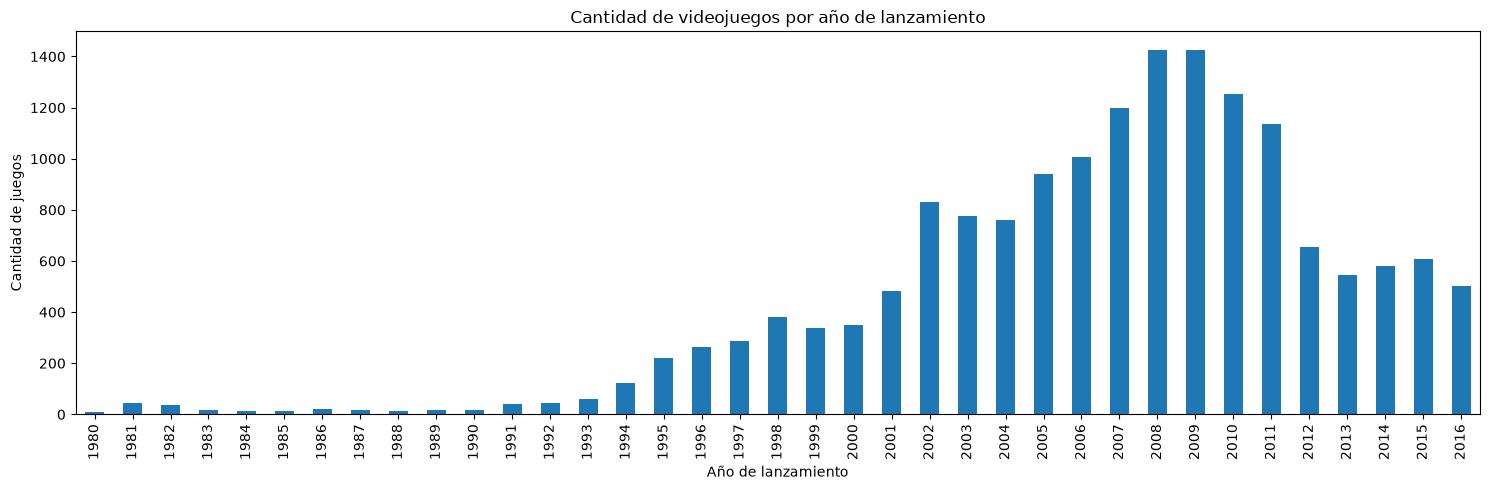

In [3]:
import matplotlib.pyplot as plt

# Los años ausentes no aparecen en el agrupamiento; se reportan por separado.
games_per_year = games.groupby('year_of_release', dropna=True)['name'].count()
print(games_per_year)

missing_years = games['year_of_release'].isna().sum()
print(f'Juegos sin año de lanzamiento: {missing_years}')

games_per_year.plot(kind='bar', figsize=(15, 5))
plt.title('Cantidad de videojuegos por año de lanzamiento')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Cantidad de juegos')
plt.tight_layout()
plt.savefig('../resultados/videojuegos_por_anio.png', dpi=300, bbox_inches='tight')
plt.show()


La mayoría de los juegos se concentran en los años más recientes, sobre todo después del 2000. En los primeros años hay muy pocos registros, por lo que no son tan representativos. A partir de mediados de los 90 y especialmente en los 2000, los lanzamientos aumentan notablemente. Por ello, los periodos más recientes resultan más confiables para el análisis.

# Paso 3. Analiza los datos

Top 5 plataformas con más ventas:
 Index(['PS2', 'X360', 'PS3', 'Wii', 'DS'], dtype='str', name='platform')
    year_of_release platform  total_sales
0              1985       DS         0.02
1              2000      PS2        39.17
2              2001      PS2       166.43
3              2002      PS2       205.38
4              2003      PS2       184.31
5              2004       DS        17.27
6              2004      PS2       211.81
7              2005       DS       130.14
8              2005      PS2       160.66
9              2005     X360         8.25
10             2006       DS       119.81
11             2006      PS2       103.42
12             2006      PS3        20.96
13             2006      Wii       137.15
14             2006     X360        51.62
15             2007       DS       146.94
16             2007      PS2        75.99
17             2007      PS3        73.19
18             2007      Wii       152.77
19             2007     X360        95.41
20        

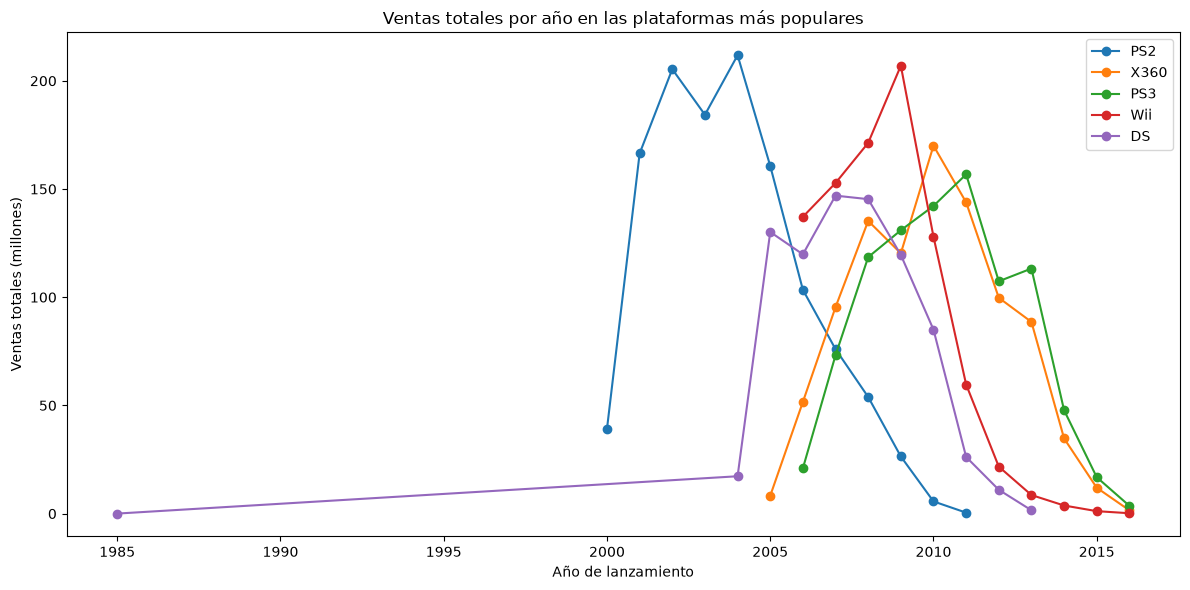

In [4]:
platform_sales = games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

top_platforms = platform_sales.head(5).index
print("Top 5 plataformas con más ventas:\n", top_platforms)

top_data = games[games['platform'].isin(top_platforms)]
#print(top_data)

sales_by_year = top_data.groupby(['year_of_release','platform'])['total_sales'].sum().reset_index()
print(sales_by_year)

plt.figure(figsize=(12,6))
for platform in top_platforms:
    data=sales_by_year[sales_by_year['platform']==platform]
    plt.plot(data['year_of_release'], data['total_sales'], marker='o', label = platform)
    plt.title("Ventas totales por año en las plataformas más populares")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Ventas totales (millones)")
plt.legend()
plt.tight_layout()
plt.savefig('../resultados/ventas_plataformas_populares.png', dpi=300, bbox_inches='tight')
plt.show()

In [5]:

platform_year_sales = games.groupby(['platform', 'year_of_release'])['total_sales'].sum().reset_index()

platform_year_sales = platform_year_sales.dropna(subset=['year_of_release'])

platform_life = platform_year_sales.groupby('platform').agg(
    first_year=('year_of_release', 'min'),
    last_year=('year_of_release', 'max')
).reset_index()

platform_life['duration'] = platform_life['last_year'] - platform_life['first_year']

print(platform_life.sort_values('duration', ascending=False))



   platform  first_year  last_year  duration
13       PC        1985       2016        31
4        DS        1985       2013        28
5        GB        1988       2001        13
11      NES        1983       1994        11
28     X360        2005       2016        11
19      PSP        2004       2015        11
16      PS2        2000       2011        11
17      PS3        2006       2016        10
3        DC        1998       2008        10
26      Wii        2006       2016        10
23     SNES        1990       1999         9
0      2600        1980       1989         9
15       PS        1994       2003         9
29       XB        2000       2008         8
6       GBA        2000       2007         7
10      N64        1996       2002         6
7        GC        2001       2007         6
20      PSV        2011       2016         5
21      SAT        1994       1999         5
2       3DS        2011       2016         5
8       GEN        1990       1994         4
27     Wii

En promedio, las plataformas de videojuegos tardan alrededor de 9 a 10 año en desaparecer del mercado desde su lanzamiento. Algunas, como PC o Nintendo DS, tuvieron una vida mucho más larga (más de 25 años), mientras que otras, como PCFX o TG16 duraron apenas 1 o 2 años.

Plataformas activas entre 2007-2016:
['3DS', 'DS', 'PC', 'PS2', 'PS3', 'PS4', 'PSP', 'PSV', 'Wii', 'WiiU', 'X360', 'XOne']

Tabla filtrada:
platform           3DS      DS     PC    PS2     PS3     PS4    PSP    PSV  \
year_of_release                                                              
2007              0.00  146.94   9.28  75.99   73.19    0.00  46.93   0.00   
2008              0.00  145.31  12.42  53.90  118.52    0.00  34.55   0.00   
2009              0.00  119.54  16.91  26.40  130.93    0.00  37.78   0.00   
2010              0.00   85.02  24.28   5.64  142.17    0.00  35.04   0.00   
2011             63.20   26.18  35.03   0.45  156.78    0.00  17.82   4.63   
2012             51.36   11.01  23.22   0.00  107.36    0.00   7.69  16.19   
2013             56.57    1.54  12.38   0.00  113.25   25.99   3.14  10.59   
2014             43.76    0.00  13.28   0.00   47.76  100.00   0.24  11.90   
2015             27.78    0.00   8.52   0.00   16.82  118.90   0.12   6.25   
20

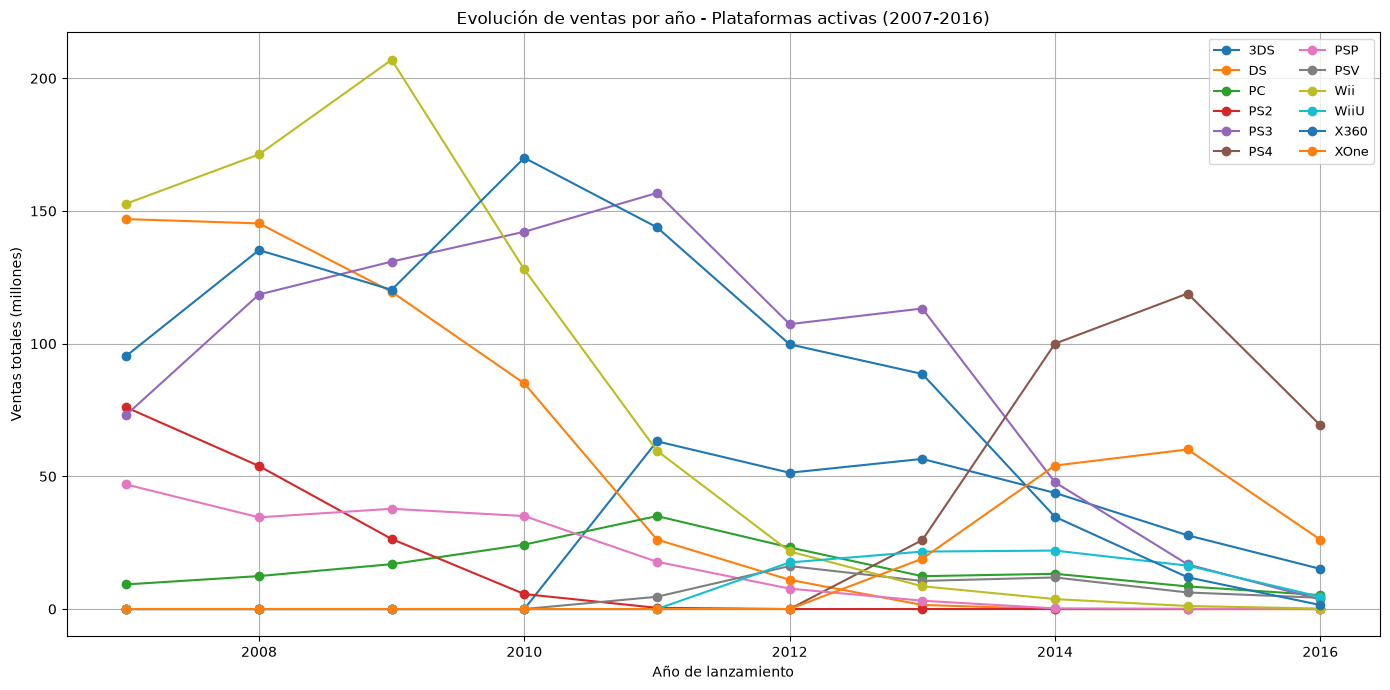

In [6]:
recent_games = games[(games['year_of_release'] >= 2007) & (games['year_of_release'] <= 2016)].copy()

sales_by_year = (
    recent_games.groupby(['platform', 'year_of_release'])['total_sales']
    .sum()
    .reset_index()
)

sales_table = sales_by_year.pivot(index='year_of_release', columns='platform', values='total_sales').fillna(0)

active_platforms = sales_table.columns[(sales_table > 0).sum() > 2]
sales_table = sales_table[active_platforms]

print("Plataformas activas entre 2007-2016:")
print(list(active_platforms))
print("\nTabla filtrada:")
print(sales_table)

plt.figure(figsize=(14,7))
for platform in active_platforms:
    plt.plot(sales_table.index, sales_table[platform], marker='o', label=platform)

plt.title('Evolución de ventas por año - Plataformas activas (2007-2016)')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas totales (millones)')
plt.legend(ncol=2, fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.savefig('../resultados/evolucion_ventas_plataformas.png', dpi=300, bbox_inches='tight')
plt.show()



Entre 2007 y 2016, las plataformas con mayores ventas fueron Wii, Xbox 360 y PlayStation 3, aunque sus cifras comenzaron a disminuir después de 2012. En cambio, PlayStation 4, Xbox One y Nintendo 3DS mostraron un crecimiento constante en los últimos años del período, posicionándose como las plataformas más rentables y con mejor proyección a futuro.

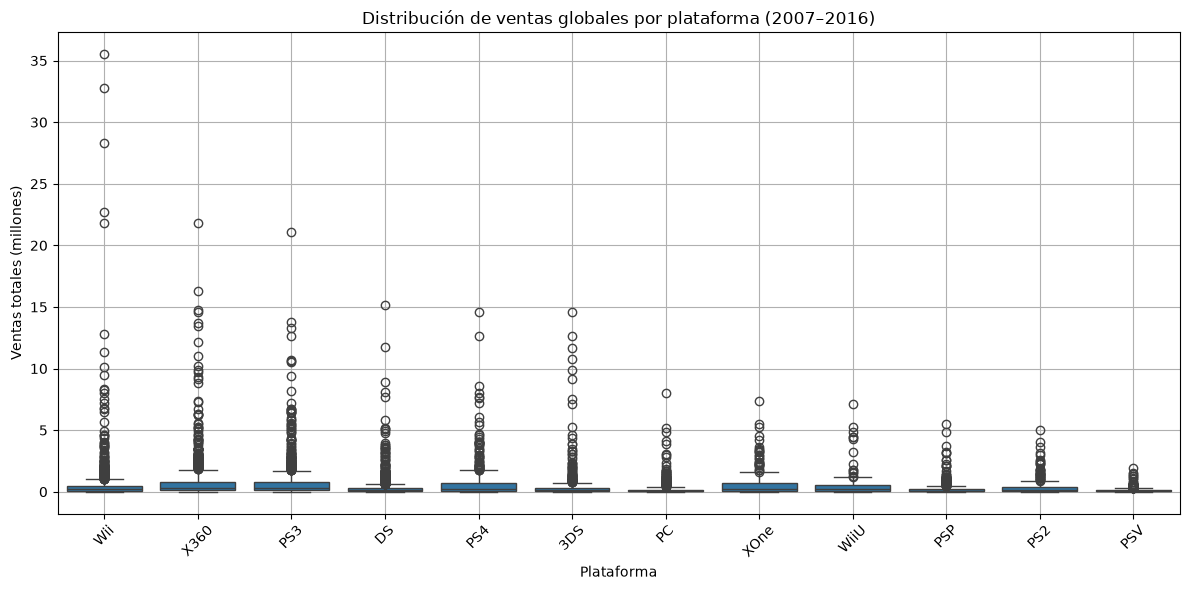

In [7]:
import seaborn as sns
plt.figure(figsize=(12,6))
sns.boxplot(data=recent_games[recent_games['platform'].isin(active_platforms)],
            x='platform', y='total_sales')

plt.title('Distribución de ventas globales por plataforma (2007–2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas totales (millones)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig('../resultados/distribucion_ventas_plataforma.png', dpi=300, bbox_inches='tight')
plt.show()

Las diferencias entre plataformas son notorias, algunas como Wii, PS3 y X360 muestran una mayor variabilidad en las ventas, con algunos juegos que alcanzan picos mucho más altos que el promedio. En contraste, plataformas más nuevas como PS4 y XOne tienen ventas más estables pero con medianas ligeramente más altas.

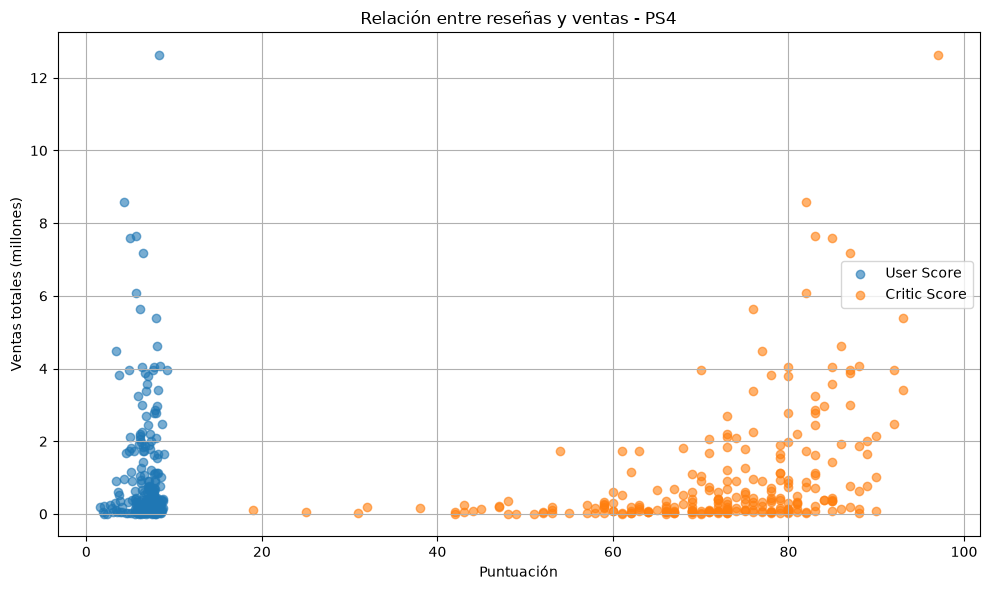

Correlación entre User Score y Ventas: -0.03195711020455643
Correlación entre Critic Score y Ventas: 0.4065679020617816


In [8]:

platform_data = recent_games[recent_games['platform'] == 'PS4']

plt.figure(figsize=(10,6))
plt.scatter(platform_data['user_score'], platform_data['total_sales'], alpha=0.6, label='User Score')
plt.scatter(platform_data['critic_score'], platform_data['total_sales'], alpha=0.6, label='Critic Score')

plt.title('Relación entre reseñas y ventas - PS4')
plt.xlabel('Puntuación')
plt.ylabel('Ventas totales (millones)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('../resultados/resenas_y_ventas_ps4.png', dpi=300, bbox_inches='tight')
plt.show()

print('Correlación entre User Score y Ventas:', platform_data['user_score'].corr(platform_data['total_sales']))
print('Correlación entre Critic Score y Ventas:', platform_data['critic_score'].corr(platform_data['total_sales']))


En los juegos de PS4 analizados, la relación entre la puntuación de usuarios y las ventas parece débil. La correlación mide asociación lineal, no causalidad; además, el resultado se calcula únicamente con juegos que tienen una puntuación de usuarios disponible. Conviene comparar esta observación con la correlación entre ventas y puntuación de críticos.


In [9]:
ps4_games = recent_games[recent_games['platform']=='PS4']['name'].unique()

comparasion = recent_games[recent_games['name'].isin(ps4_games) & 
                          (recent_games['platform'] != 'PS4')]

sales_comparasion = comparasion.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print(sales_comparasion)

platform
PS3     151.37
XOne    129.36
X360    125.57
PC       34.43
WiiU     12.68
PSV      11.85
Wii      11.22
3DS       5.50
PSP       1.16
DS        0.44
Name: total_sales, dtype: float64


platform
PS4     314.14
PS3     151.37
XOne    129.36
X360    125.57
PC       34.43
WiiU     12.68
PSV      11.85
Wii      11.22
3DS       5.50
PSP       1.16
DS        0.44
Name: total_sales, dtype: float64


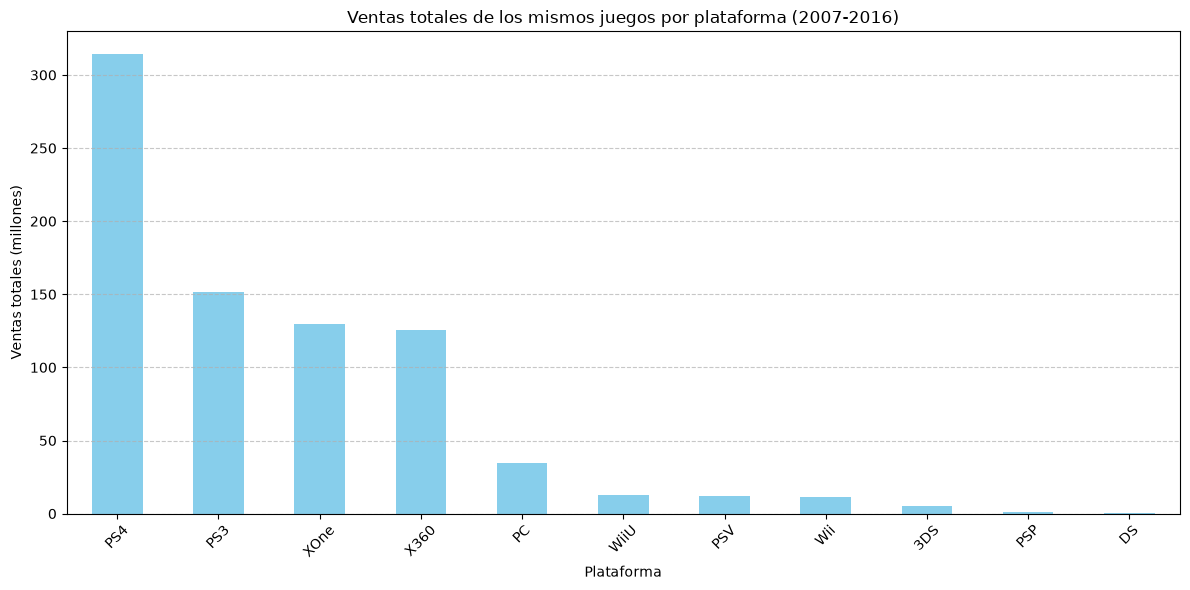

In [10]:
ps4_games = recent_games[recent_games['platform'] == 'PS4']['name'].unique()

comparison = recent_games[recent_games['name'].isin(ps4_games)]

sales_comparison = comparison.groupby('platform')['total_sales'].sum().sort_values(ascending=False)

print(sales_comparison)

plt.figure(figsize=(12,6))
sales_comparison.plot(kind='bar', color='skyblue')
plt.title('Ventas totales de los mismos juegos por plataforma (2007-2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas totales (millones)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('../resultados/ventas_mismos_juegos_plataforma.png', dpi=300, bbox_inches='tight')
plt.show()

PS4 vende mucho más que las demás, con 314 millones, seguida de PS3, XOne y X360 que todavía venden bastante. PC y WiiU tienen ventas medianas, mientras que PSV, Wii, 3DS, PSP y DS venden muy poco. En general, las consolas nuevas venden más y las viejas o portátiles menos.

Ventas totales por género (2007-2016):
genre
Action          1050.59
Shooter          678.80
Sports           658.07
Misc             487.89
Role-Playing     465.03
Racing           265.19
Platform         230.45
Simulation       199.13
Fighting         166.00
Adventure        129.99
Puzzle            79.18
Strategy          68.99
Name: total_sales, dtype: float64


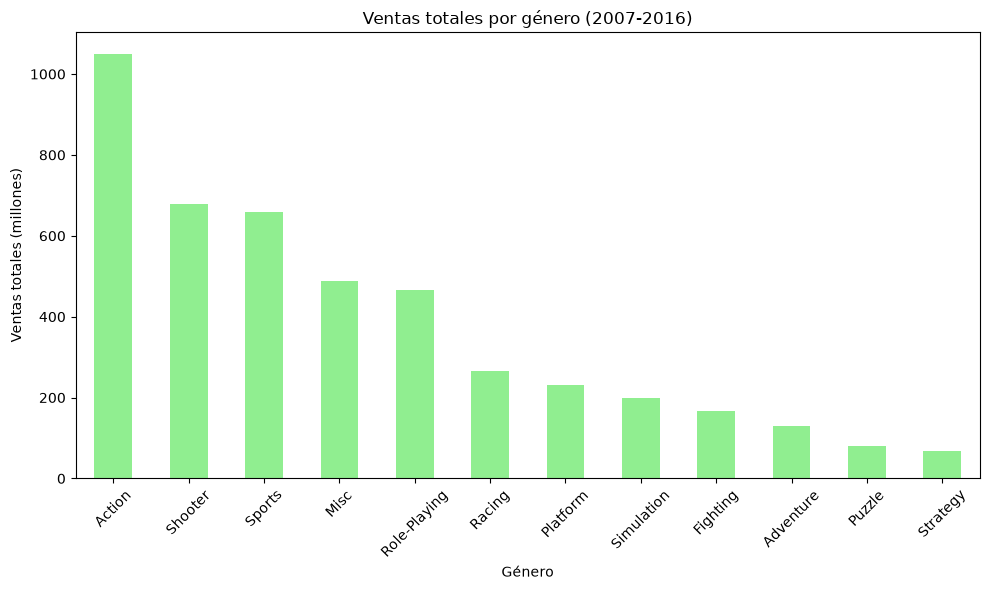

In [11]:
genre_sales = recent_games.groupby('genre')['total_sales'].sum().sort_values(ascending=False)
print("Ventas totales por género (2007-2016):")
print(genre_sales)

plt.figure(figsize=(10, 6))
genre_sales.plot(kind='bar', color='lightgreen')
plt.title('Ventas totales por género (2007-2016)')
plt.xlabel('Género')
plt.ylabel('Ventas totales (millones)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../resultados/ventas_por_genero.png', dpi=300, bbox_inches='tight')
plt.show()

En el periodo analizado, Action, Shooter y Sports destacan por sus ventas globales acumuladas. Sin embargo, las ventas totales pueden depender de cuántos juegos se publicaron en cada género. Para comparar el rendimiento típico, también es útil revisar las ventas promedio o medianas por juego.


# Paso 4. Crea un perfil de usuario para cada región

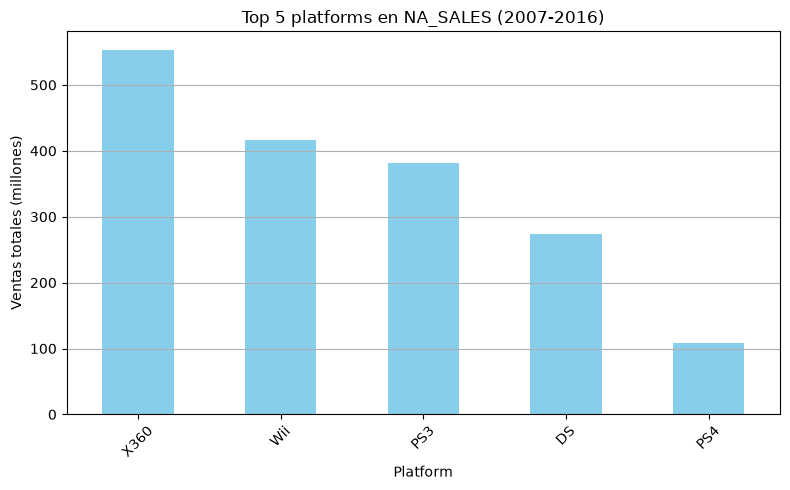

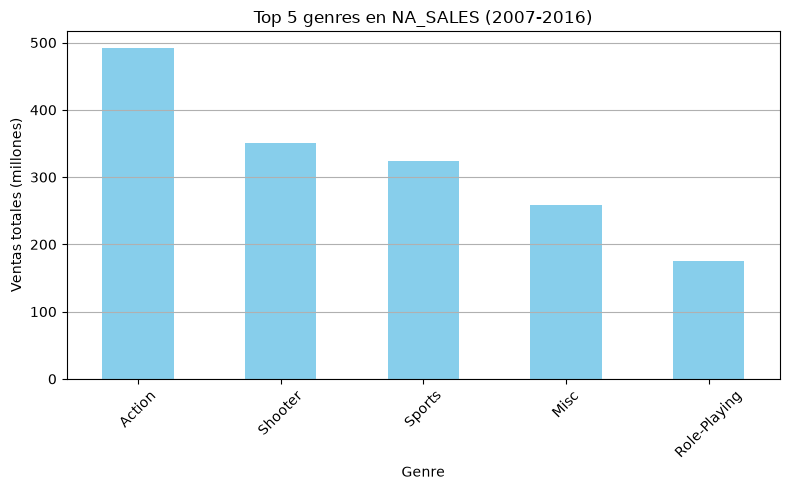

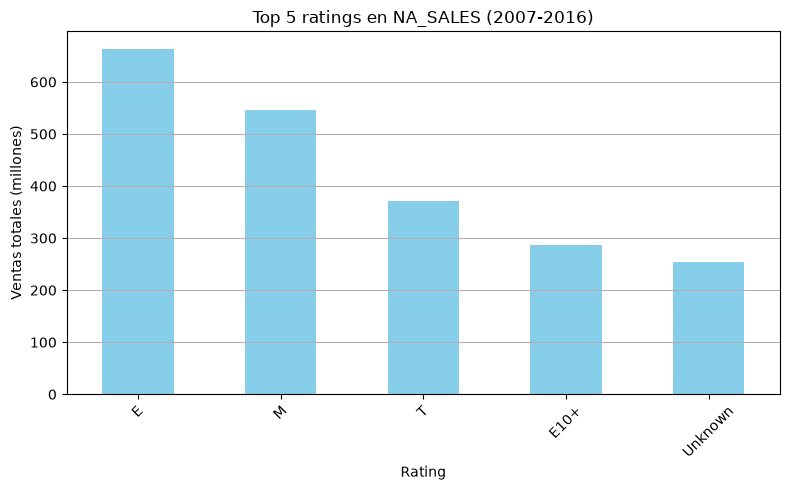

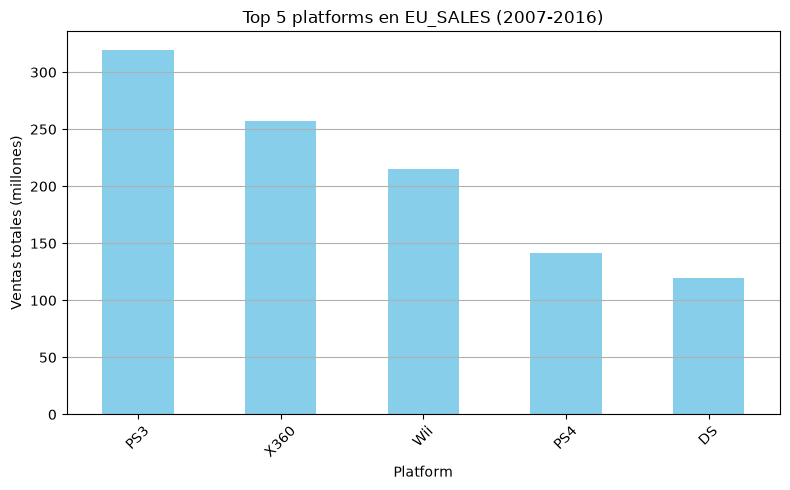

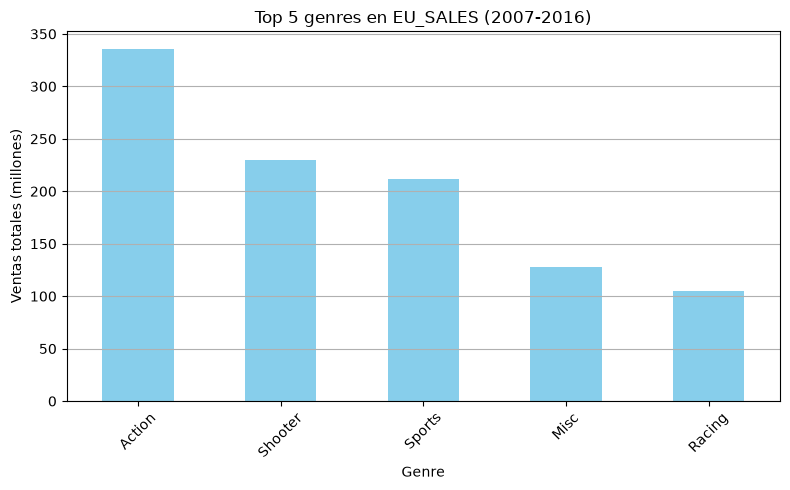

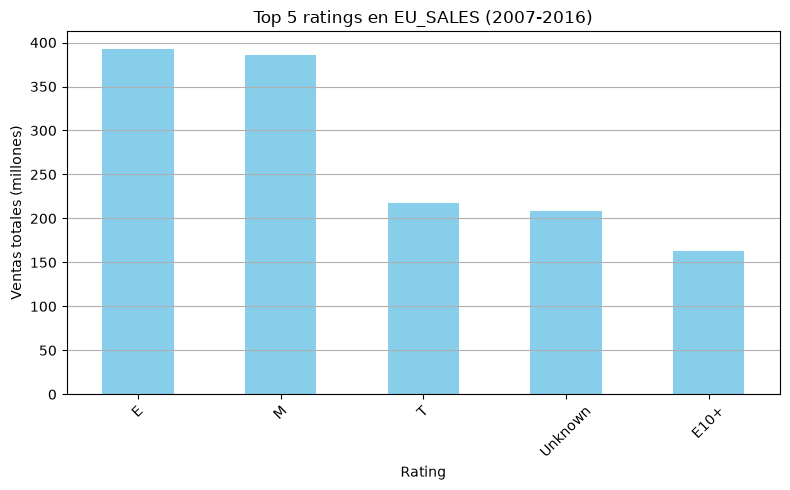

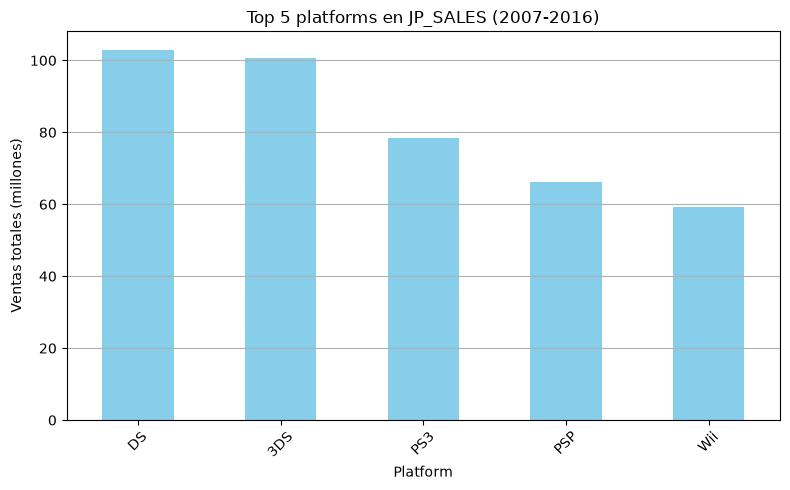

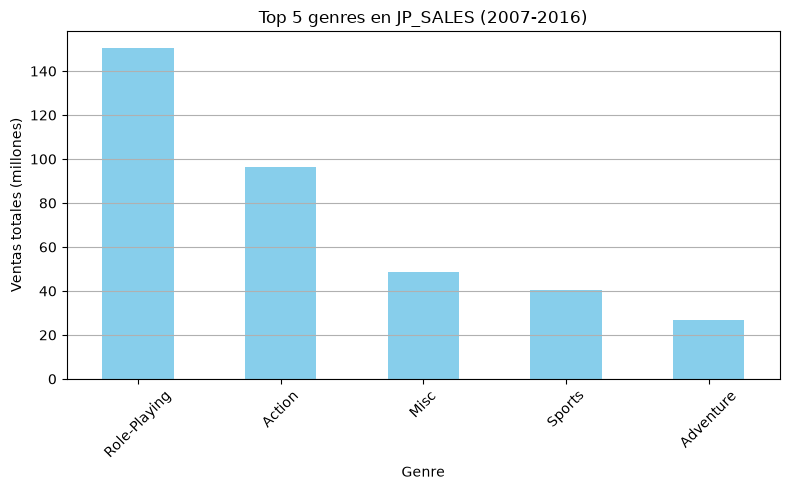

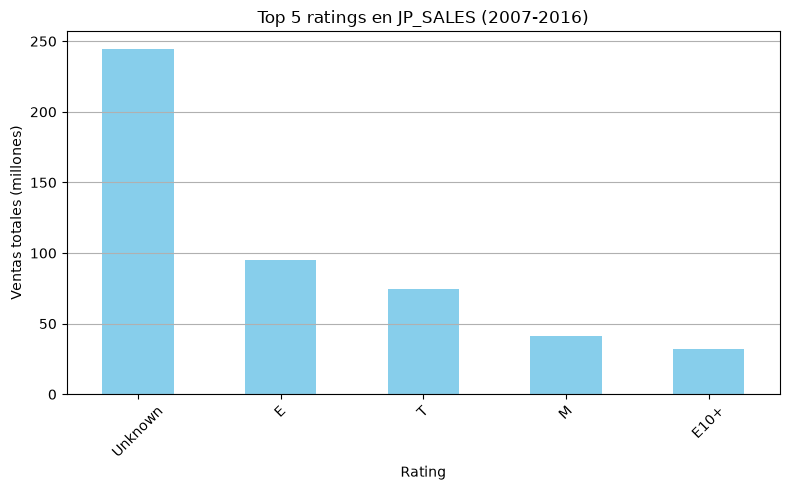

In [12]:
regions = ['na_sales', 'eu_sales', 'jp_sales']
categories = ['platform', 'genre', 'rating']

for region in regions:
    for cat in categories:
      
        top_items = recent_games.groupby(cat)[region].sum().sort_values(ascending=False).head(5)

        
        plt.figure(figsize=(8,5))
        top_items.plot(kind='bar', color='skyblue')
        plt.title(f'Top 5 {cat}s en {region.upper()} (2007-2016)')
        plt.ylabel('Ventas totales (millones)')
        plt.xlabel(cat.capitalize())
        plt.xticks(rotation=45)
        plt.grid(axis='y')
        plt.tight_layout()
        filename = f"top5_{cat}_{region}.png"
        plt.savefig(f'../resultados/{filename}', dpi=300, bbox_inches='tight')
        plt.show()
   

1. Las plataformas más populares cambian según la región. PS4, PS3 y X360 dominan en NA y UE, mientras que DS y 3DS son más fuertes en JP, reflejando diferencias en gustos y disponibilidad de consolas.

2. En NA y EU, los juegos de Action, Shooter y Sports lideran las ventas, mientras que en JP predominan los Role-Playing y Action, mostrando que los jugadores japoneses prefieren juegos de rol y en Occidente los de acción y deportes.

3. Las ventas se ven afectadas por la clasificación de edad: los juegos para todos (E) venden más en NA y EU, mientras que los títulos para adolescentes o adultos tienen menor demanda, en JP, la clasificación ESRB tiene menos impacto debido a diferencias en el sistema de calificación.

# Paso 5. Prueba las siguientes hipótesis:

In [13]:
from scipy import stats
import numpy as np
xone_scores = recent_games[recent_games['platform'] == 'XOne']['user_score'].dropna()
pc_scores = recent_games[recent_games['platform'] == 'PC']['user_score'].dropna()

t_stat, p_value = stats.ttest_ind(xone_scores, pc_scores, equal_var=False)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: las calificaciones promedio son diferentes.")
else:
    print("No podemos rechazar la hipótesis nula: las calificaciones promedio son similares.")


T-statistic: -2.0215585703121315
P-value: 0.044018928589261715
Rechazamos la hipótesis nula: las calificaciones promedio son diferentes.


In [14]:
action_scores = recent_games[recent_games['genre'] == 'Action']['user_score'].dropna()
sports_scores = recent_games[recent_games['genre'] == 'Sports']['user_score'].dropna()

t_stat, p_value = stats.ttest_ind(action_scores, sports_scores, equal_var=False)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")

# Interpretación
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: las calificaciones promedio son diferentes.")
else:
    print("No podemos rechazar la hipótesis nula: las calificaciones promedio son similares.")


T-statistic: 6.661247173505023
P-value: 4.5406655100552285e-11
Rechazamos la hipótesis nula: las calificaciones promedio son diferentes.


Hipótesis resumida:
H₀: Las calificaciones promedio de Action y Sports son iguales.
H₁: Las calificaciones promedio de Action y Sports son diferentes.

Criterio:
Usamos prueba t para muestras independientes porque comparamos promedios de dos grupos distintos.
Si el p-value < 0.05, rechazamos H₀, si es mayor, no rechazamos H₀.

# Paso 6. Escribe una conclusión general

**Conclusión general:**

Entre 2007 y 2016, las plataformas con mayores ventas acumuladas en el periodo analizado fueron PS3, X360, Wii, DS y PS4, con PS4 y XOne mostrando crecimiento reciente. Los géneros más rentables fueron Acción, Shooter y Deportes, mientras que Puzzle y Strategy tuvieron ventas bajas. Las reseñas de críticos influyen más en las ventas que las de los usuarios. Además, las preferencias varían por región y la clasificación ESRB afecta las ventas. Estos hallazgos permiten enfocar campañas y elegir plataformas y géneros con mayor potencial de éxito.\n\n**Limitaciones:** las ventas históricas no garantizan el rendimiento futuro. Además, las calificaciones ausentes se conservaron sin imputación, por lo que las comparaciones de puntuaciones utilizan solo los registros disponibles.